In [ ]:
"""
BCSE331P - Lab Assessment 4: Bivariate Analysis (Python)
NAME: P BALAJI SUBRAMANIAN
REG NO: 23BDS0271
"""

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
CSV_PATH = "orange_juice_withmissing.csv"

In [2]:
# 1. Load dataset and clean (median / mode imputation, drop duplicates)
df = pd.read_csv(CSV_PATH)
num_all = df.select_dtypes(include=np.number).columns
df[num_all] = df[num_all].fillna(df[num_all].median())
df = df.drop_duplicates().reset_index(drop=True)
for c in ["StoreID", "STORE", "SpecialCH", "SpecialMM"]:
    df[c] = df[c].astype(int).astype(str)
print(df.shape)

(1045, 18)


In [3]:
# 2. Contingency table: Purchase vs Store7
ct = pd.crosstab(df["Store7"], df["Purchase"])
print("Contingency table (Store7 x Purchase):\n", ct, "\n")

Contingency table (Store7 x Purchase):
 Purchase   CH   MM
Store7            
No        375  327
Yes       264   79 



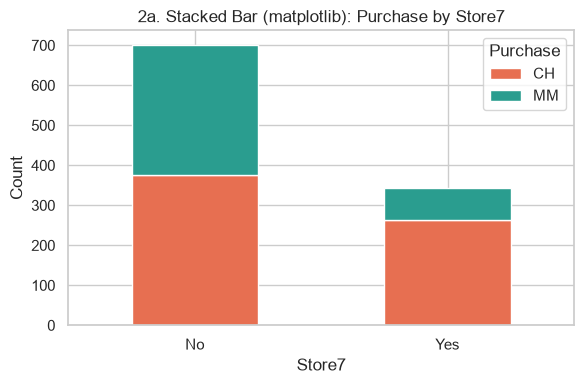

In [4]:
# 2a. Stacked bar - Base matplotlib
ct.plot(kind="bar", stacked=True, color=["#e76f51", "#2a9d8f"], figsize=(6, 4))
plt.title("2a. Stacked Bar (matplotlib): Purchase by Store7")
plt.xlabel("Store7"); plt.ylabel("Count"); plt.xticks(rotation=0); plt.legend(title="Purchase")
plt.tight_layout(); plt.show()

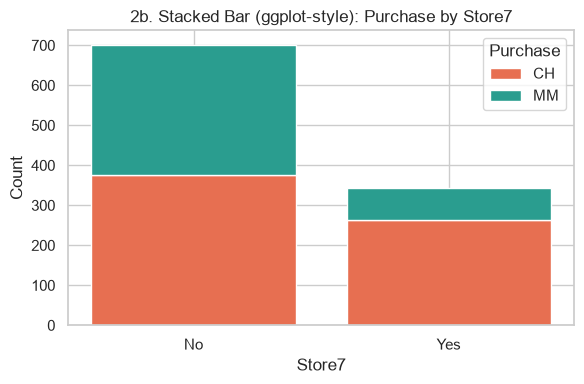

In [5]:
# 2b. Stacked bar - seaborn (ggplot2-style: geom_bar(position="stack"))
tmp = ct.reset_index().melt(id_vars="Store7", var_name="Purchase", value_name="Count")
pivot = tmp.pivot(index="Store7", columns="Purchase", values="Count")
fig, ax = plt.subplots(figsize=(6, 4))
bottom = np.zeros(len(pivot))
for col, colr in zip(pivot.columns, ["#e76f51", "#2a9d8f"]):
    ax.bar(pivot.index, pivot[col], bottom=bottom, label=col, color=colr)
    bottom += pivot[col].values
ax.set_title("2b. Stacked Bar (ggplot-style): Purchase by Store7")
ax.set_xlabel("Store7"); ax.set_ylabel("Count"); ax.legend(title="Purchase")
plt.tight_layout(); plt.show()

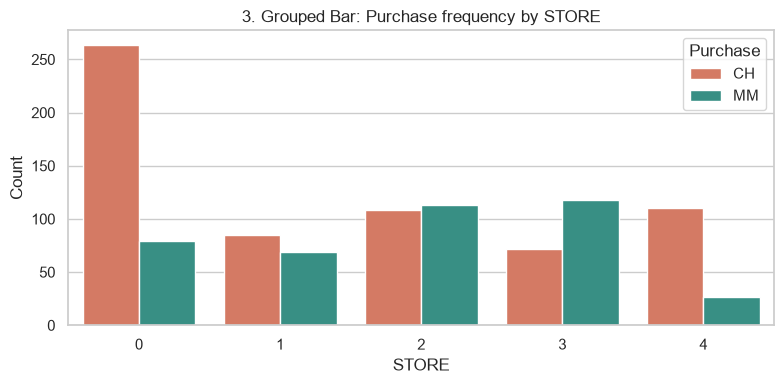

In [6]:
# 3. Grouped (side-by-side) bar: STORE vs Purchase
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="STORE", hue="Purchase", order=sorted(df["STORE"].unique()),
              palette=["#e76f51", "#2a9d8f"])
plt.title("3. Grouped Bar: Purchase frequency by STORE")
plt.xlabel("STORE"); plt.ylabel("Count")
plt.tight_layout(); plt.show()

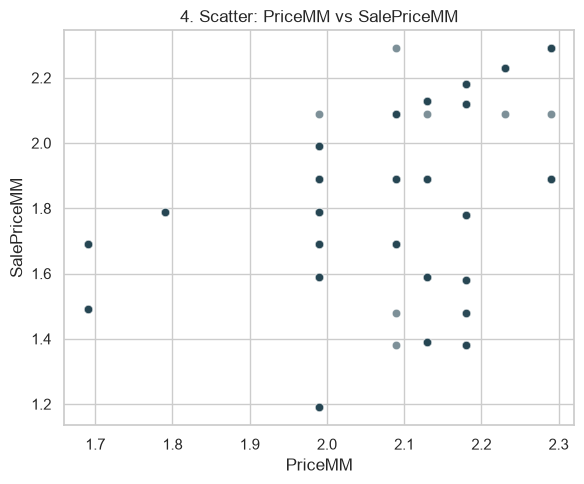

In [7]:
# 4. Scatter plot: two numeric variables
plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x="PriceMM", y="SalePriceMM", alpha=0.6, color="#264653")
plt.title("4. Scatter: PriceMM vs SalePriceMM")
plt.xlabel("PriceMM"); plt.ylabel("SalePriceMM")
plt.tight_layout(); plt.show()

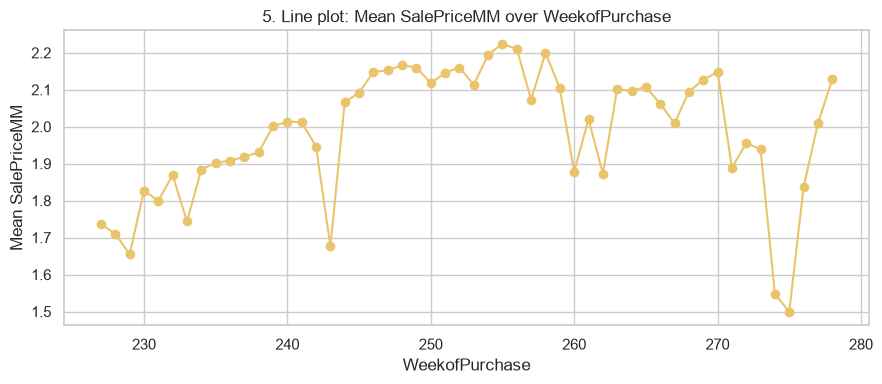

In [8]:
# 5. Line plot: average SalePriceMM trend over weeks
trend = df.groupby("WeekofPurchase")["SalePriceMM"].mean().reset_index()
plt.figure(figsize=(9, 4))
plt.plot(trend["WeekofPurchase"], trend["SalePriceMM"], marker="o", color="#e9c46a")
plt.title("5. Line plot: Mean SalePriceMM over WeekofPurchase")
plt.xlabel("WeekofPurchase"); plt.ylabel("Mean SalePriceMM")
plt.tight_layout(); plt.show()

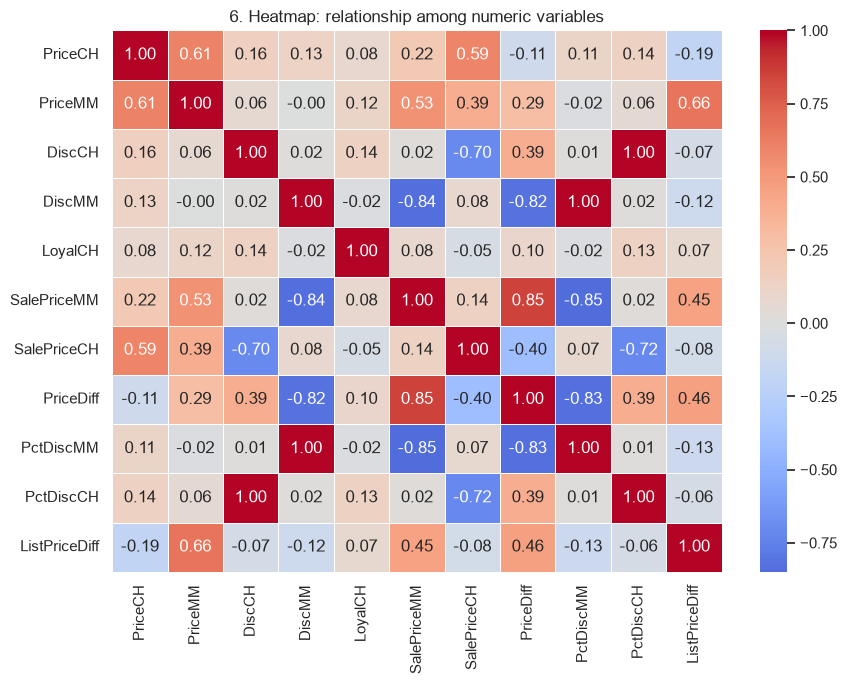

In [9]:
# 6. Heatmap of numeric variables
num_cols = ["PriceCH", "PriceMM", "DiscCH", "DiscMM", "LoyalCH", "SalePriceMM",
            "SalePriceCH", "PriceDiff", "PctDiscMM", "PctDiscCH", "ListPriceDiff"]
corr = df[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", linewidths=0.5)
plt.title("6. Heatmap: relationship among numeric variables")
plt.tight_layout(); plt.show()

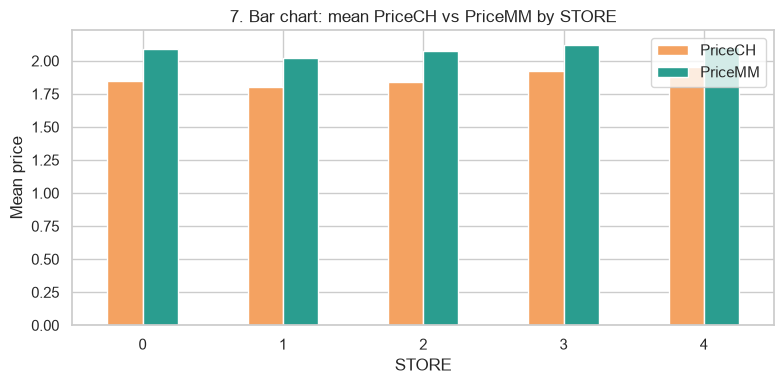

In [10]:
# 7. Bar chart comparing values of two variables (mean prices by STORE)
means = df.groupby("STORE")[["PriceCH", "PriceMM"]].mean().reset_index()
means.plot(x="STORE", kind="bar", figsize=(8, 4), color=["#f4a261", "#2a9d8f"])
plt.title("7. Bar chart: mean PriceCH vs PriceMM by STORE")
plt.xlabel("STORE"); plt.ylabel("Mean price"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

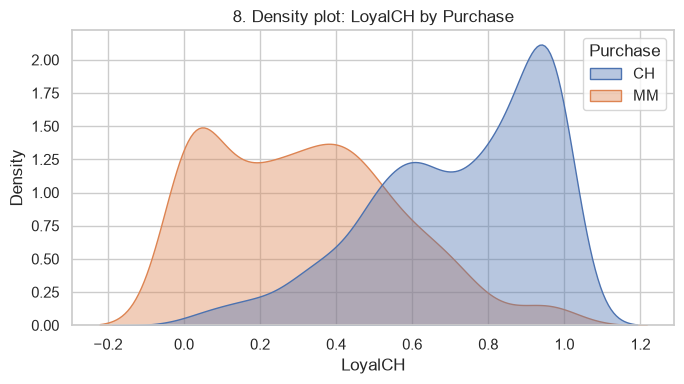

In [11]:
# 8. Density plot: numeric across categories
plt.figure(figsize=(7, 4))
sns.kdeplot(data=df, x="LoyalCH", hue="Purchase", fill=True, common_norm=False, alpha=0.4)
plt.title("8. Density plot: LoyalCH by Purchase")
plt.tight_layout(); plt.show()

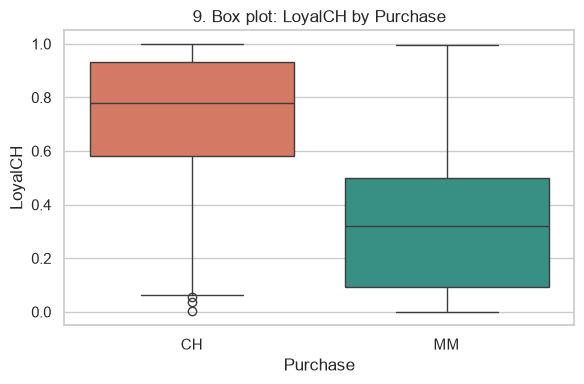

In [12]:
# 9. Box plot
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Purchase", y="LoyalCH", palette=["#e76f51", "#2a9d8f"], hue="Purchase", legend=False)
plt.title("9. Box plot: LoyalCH by Purchase")
plt.tight_layout(); plt.show()

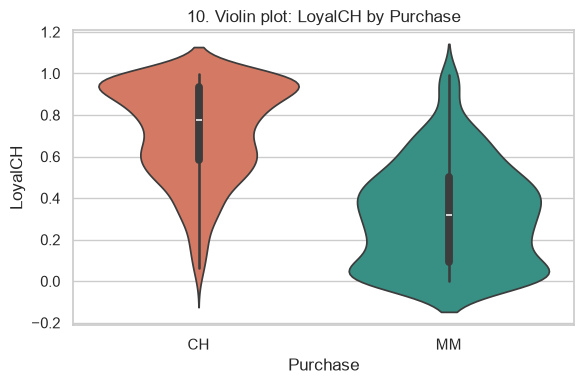

In [13]:
# 10. Violin plot
plt.figure(figsize=(6, 4))
sns.violinplot(data=df, x="Purchase", y="LoyalCH", palette=["#e76f51", "#2a9d8f"], hue="Purchase", legend=False)
plt.title("10. Violin plot: LoyalCH by Purchase")
plt.tight_layout(); plt.show()

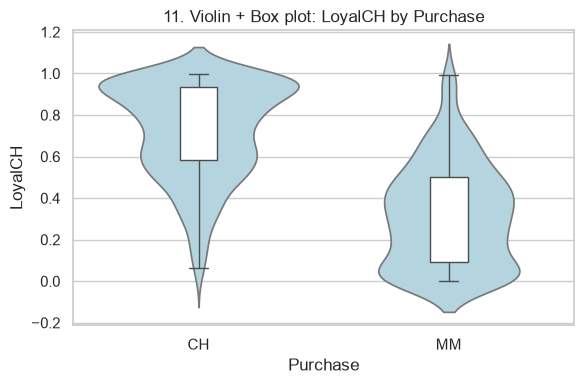

In [14]:
# 11. Violin + box combined
plt.figure(figsize=(6, 4))
sns.violinplot(data=df, x="Purchase", y="LoyalCH", inner=None, color="lightblue")
sns.boxplot(data=df, x="Purchase", y="LoyalCH", width=0.15, showcaps=True,
            boxprops={"facecolor": "white", "zorder": 3}, showfliers=False)
plt.title("11. Violin + Box plot: LoyalCH by Purchase")
plt.tight_layout(); plt.show()

12. Correlation matrix:
              PriceCH  PriceMM  LoyalCH  SalePriceMM  SalePriceCH  PriceDiff
PriceCH        1.000    0.609    0.078        0.220        0.590     -0.107
PriceMM        0.609    1.000    0.119        0.534        0.386      0.293
LoyalCH        0.078    0.119    1.000        0.077       -0.054      0.102
SalePriceMM    0.220    0.534    0.077        1.000        0.140      0.851
SalePriceCH    0.590    0.386   -0.054        0.140        1.000     -0.396
PriceDiff     -0.107    0.293    0.102        0.851       -0.396      1.000 



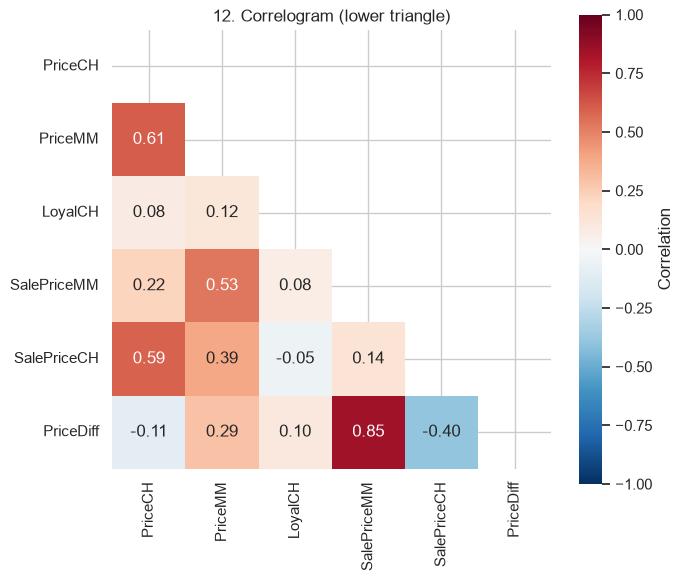

In [15]:
# 12. Correlation matrix and correlogram
sub = ["PriceCH", "PriceMM", "LoyalCH", "SalePriceMM", "SalePriceCH", "PriceDiff"]
cm = df[sub].corr()
print("12. Correlation matrix:\n", cm.round(3), "\n")
mask = np.triu(np.ones_like(cm, dtype=bool))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, cbar_kws={"label": "Correlation"})
plt.title("12. Correlogram (lower triangle)")
plt.tight_layout(); plt.show()

In [16]:
# 13. Titles, axis labels, legends and parameters are set on every plot above.
print("13. All plots include titles, axis labels, legends and graphical parameters.")

13. All plots include titles, axis labels, legends and graphical parameters.
